# Speed / memory figure

FPS and peak GPU memory vs number of views at 100 query points, from the A100 speed benchmark
(`posetail-next/benchmark_speed`, 96-frame Point Odyssey clip). FPS is on a log scale (MVTracker with DUSt3R depth is < 1 FPS).
Point Odyssey has 9 cameras; the 10-view point duplicates one camera.

In [1]:
import os
import json
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

matplotlib.rcParams.update({
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
})

In [2]:
RESULTS = Path('/groups/karashchuk/home/karashchukl/projects/posetail/posetail-next/'
               'benchmark_speed/results/a100_mvtracker_20261026_133500')
outpath = 'figures'
KPTS = 100

method_dict = {
    'cotracker':        'CoTracker3 Baseline',
    'mvtracker-dust3r': 'MVTracker (DUSt3R depth)',
    'arrow':            'ARROW',
    'tracktail':        'Tracktail (Ours)',
}
palette = sns.color_palette('colorblind', n_colors=12)
colors = {   # same colors as figure_ncams for CoTracker3 / MVTracker (DUSt3R) / Tracktail
    'cotracker':        palette[9],
    'mvtracker-dust3r': palette[3],
    'arrow':            palette[4],
    'tracktail':        palette[2],
}

rows = []
for m in method_dict:
    for line in open(RESULTS / f'{m}.jsonl'):
        r = json.loads(line)
        rows.append(dict(method=m, views=r['views'], kpts=r['kpts'], status=r['status'],
                         fps=r.get('fps'), mem=r.get('peak_alloc_gb')))
df_all = pd.DataFrame(rows).drop_duplicates(['method', 'views', 'kpts'], keep='last')
df_all = df_all[df_all['status'] == 'ok']
df = df_all.copy()
df = df[(df['kpts'] == KPTS) & (df['status'] == 'ok')].sort_values(['method', 'views'])
df.pivot(index='method', columns='views', values=['fps', 'mem']).round(2)

fps                               mem                      \
views                2      4      6      8      10    2     4      6      8    
method                                                                          
arrow             14.16   5.10   2.67   1.65   1.12  7.03  9.07  11.11  13.15   
cotracker         90.20  45.29  30.44  22.90  18.33  8.34  8.34   8.34   8.34   
mvtracker-dust3r   0.36   0.24   0.14   0.09   0.06  4.97  7.71  10.45  13.19   
tracktail         34.63  17.79  11.92   9.04   7.20  3.17  3.27   3.36   3.46   

                         
views                10  
method                   
arrow             15.19  
cotracker          8.34  
mvtracker-dust3r  15.92  
tracktail          3.65

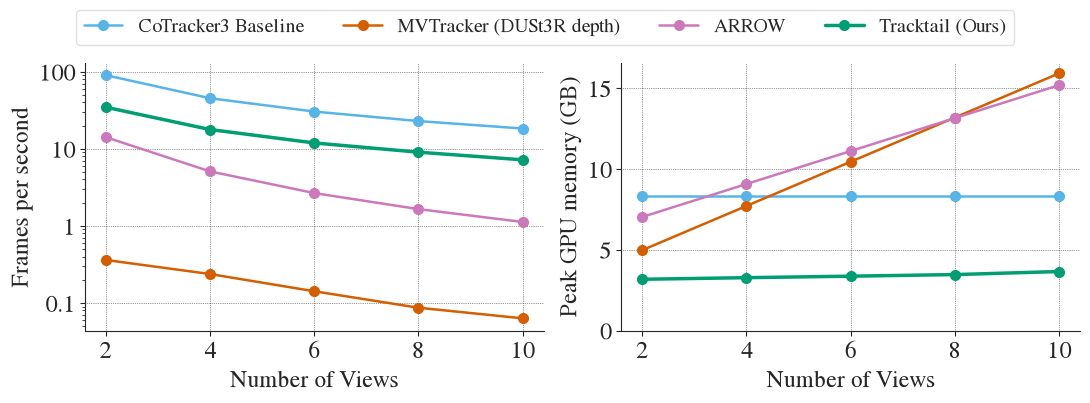

In [3]:
sns.set_style('ticks', {'font.family': 'STIXGeneral'})
fs = 17
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (key, label) in zip(axes, [('fps', 'Frames per second'), ('mem', 'Peak GPU memory (GB)')]):
    for m, name in method_dict.items():
        d = df[df['method'] == m]
        ax.plot(d['views'], d[key], marker='o', markersize=7, color=colors[m], label=name,
                linewidth=2.5 if m == 'tracktail' else 1.8, zorder=3 if m == 'tracktail' else 2)
    ax.set_xlabel('Number of Views', fontsize=fs)
    ax.set_ylabel(label, fontsize=fs)
    ax.set_xticks(sorted(df['views'].unique()))
    ax.tick_params(axis='both', labelsize=fs)
    ax.grid(True, linestyle=':', color='k', linewidth=0.5, alpha=0.8)

axes[0].set_yscale('log')
axes[0].set_yticks([0.1, 1, 10, 100])
axes[0].set_yticklabels(['0.1', '1', '10', '100'])
axes[1].set_ylim(bottom=0)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=len(labels),
           framealpha=0.7, facecolor='white', edgecolor='lightgray', fontsize=fs - 3)
plt.tight_layout(rect=(0, 0, 1, 0.9))
sns.despine()

os.makedirs(outpath, exist_ok=True)
fig.savefig(os.path.join(outpath, 'speed_memory_figure.pdf'), dpi=800, bbox_inches='tight')
fig.savefig(os.path.join(outpath, 'speed_memory_figure.png'), dpi=200, bbox_inches='tight')

### Tracktail only: FPS and memory vs views for 10 / 100 / 1000 query points

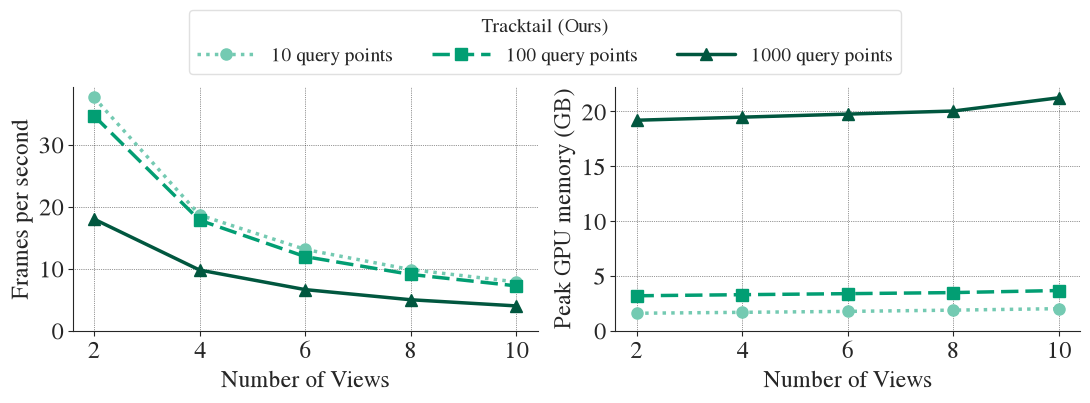

In [4]:
# light -> dark shades of the Tracktail green, plus distinct markers and dash patterns
import numpy as np
green = np.array(colors['tracktail'])
mix = lambda c, f: tuple((1 - f) * green + f * np.array(c))   # blend toward white / black
styles = {
    10:   dict(color=mix((1, 1, 1), 0.45), marker='o', linestyle=(0, (1, 1.5))),
    100:  dict(color=tuple(green),          marker='s', linestyle=(0, (5, 2))),
    1000: dict(color=mix((0, 0, 0), 0.45), marker='^', linestyle='-'),
}
tt = df_all[df_all['method'] == 'tracktail'].sort_values('views')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (key, label) in zip(axes, [('fps', 'Frames per second'), ('mem', 'Peak GPU memory (GB)')]):
    for k, st in styles.items():
        d = tt[tt['kpts'] == k]
        ax.plot(d['views'], d[key], markersize=8, linewidth=2.5, label=f'{k} query points', **st)
    ax.set_xlabel('Number of Views', fontsize=fs)
    ax.set_ylabel(label, fontsize=fs)
    ax.set_xticks(sorted(tt['views'].unique()))
    ax.tick_params(axis='both', labelsize=fs)
    ax.grid(True, linestyle=':', color='k', linewidth=0.5, alpha=0.8)
    ax.set_ylim(bottom=0)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=len(labels),
           framealpha=0.7, facecolor='white', edgecolor='lightgray', fontsize=fs - 3,
           title='Tracktail (Ours)', title_fontsize=fs - 3, handlelength=3)
plt.tight_layout(rect=(0, 0, 1, 0.84))
sns.despine()

fig.savefig(os.path.join(outpath, 'speed_memory_tracktail_figure.pdf'), dpi=800, bbox_inches='tight')
fig.savefig(os.path.join(outpath, 'speed_memory_tracktail_figure.png'), dpi=200, bbox_inches='tight')